In [86]:
%load_ext autoreload
%autoreload 2

import xr_ccew as tw
from xr_ccew.matsuno import profile_curve_frequency
import xarray as xr
import numpy as np
import pandas as pd
from scipy import ndimage
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
from scipy.signal import hilbert
from src.loading import (
    load_noaa_daily_olr,
    load_wave_filtered_olr,
    load_wave_event_record,
    load_noaa_daily_olr_spectral_power
)
from src.spectral_power import (
    spectral_power_pipeline,
    add_matsuno_curves
)
from src.constants import *

from src.wave_profiles import BOX_PROFILES as profiles

from src.plotting import save_figure, array_midpoints
from IPython.display import clear_output

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Histogram in Spectral Space

In [29]:
wave_event_records = {p: load_wave_event_record(p) for p in list(profiles.keys())}
spectral_power = load_noaa_daily_olr_spectral_power()
bg = tw.background_spectrum(0.5*(spectral_power['symmetric']+spectral_power['antisymmetric']))

Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/Kelvin.noaa_olr_event_histogram.pdf as PDF ...
Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/n1ERW.noaa_olr_event_histogram.pdf as PDF ...
Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/n0EIG.noaa_olr_event_histogram.pdf as PDF ...
Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/MRG.noaa_olr_event_histogram.pdf as PDF ...


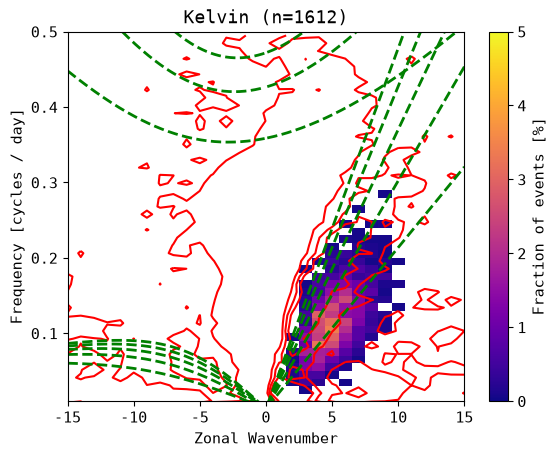

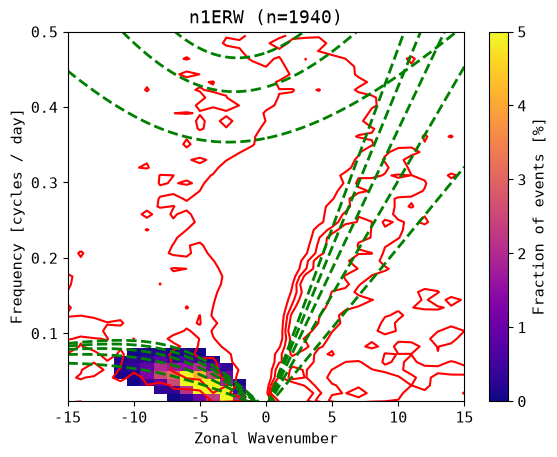

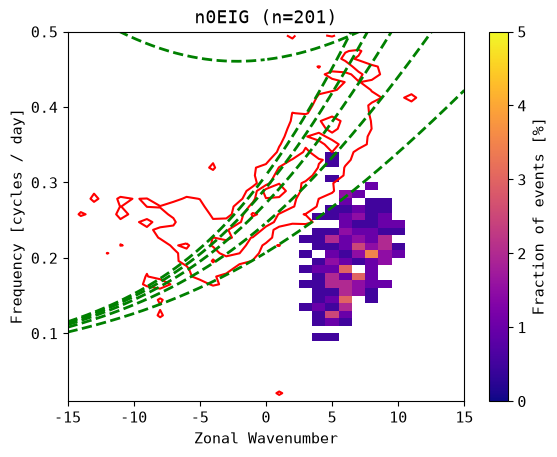

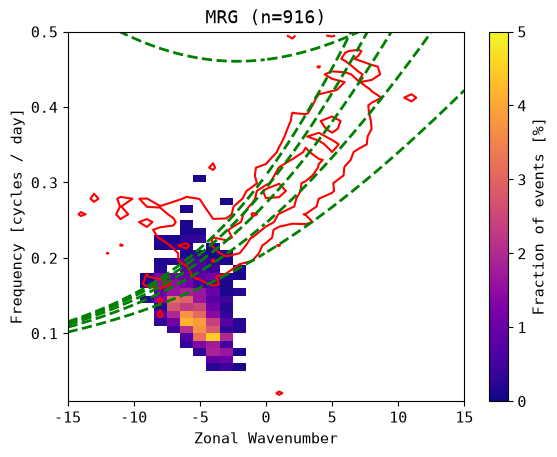

In [54]:
for wave, wave_data in profiles.items():
    if wave == 'n1WIG':
        continue
    events = wave_event_records[wave]

    event_k = np.pi / (EARTH_RADIUS * np.deg2rad(events['mean_width_deg']))
    event_cp = events['radon_m_s']
    event_omega = event_k * event_cp

    event_K = np.sign(event_cp) * event_k * EARTH_RADIUS
    event_frequency = np.abs(event_omega) * 86400 / (2 * np.pi)

    k_bins = np.arange(-15.5, 16.5, 1)
    omega_bins = np.linspace(0, 0.5, 51)  # cycles/day

    count, frequency_edges, k_edges, _  = stats.binned_statistic_2d(
        event_frequency,
        event_K,
        values = None,
        statistic='count',
        bins=[omega_bins, k_bins]        
    )

    fig, ax = plt.subplots()
    mesh = ax.pcolormesh(
        k_edges,
        frequency_edges,
        np.ma.masked_equal(100*count/count.sum(), 0),
        shading="auto",
        cmap="plasma",
        norm=mcolors.Normalize(vmin=0, vmax=5)
    )

    fig.colorbar(mesh, ax=ax, label="Fraction of events [%]")

    spectral_signal = spectral_power[wave_data.symmetry]/bg
    spectral_signal.plot.contour(
        ax=ax, 
        levels=[1.0, 1.25, 1.5],
        colors='red',
        linewidth=1.5
    )
        
    add_matsuno_curves(ax, which=wave_data.symmetry, he_list=[10, 20, 30, 40, 50], color='green', lw=2)

    ax.set_title(f'{wave} (n={events.shape[0]:.0f})')
    ax.set_xlabel('Zonal Wavenumber')
    ax.set_ylabel('Frequency [cycles / day]')
    save_figure(fig, f'{wave}.noaa_olr_event_histogram.pdf')


# Equivalent depth disparity

In [56]:
def implied_gravity_wave_speed(wave: str, phase_speed, width_deg, U=0.0):
  
    p = phase_speed - U

    assert np.isfinite(p) and np.isfinite(width_deg) and width_deg > 0

    # Width represents half a wavelength.
    k = np.pi / (EARTH_RADIUS * np.deg2rad(width_deg))

    if wave == "Kelvin":
        if p <= 0:
            return np.nan

        return p

    if wave in ("MRG", "n0EIG"):
        if wave == "MRG" and p >= 0:
            return np.nan
        if wave == "n0EIG" and p <= 0:
            return np.nan

        denominator = BETA + k**2 * p
        if denominator <= 0:
            return np.nan

        return (k * p)**2 / denominator

    if wave == "n1ERW":
        if p >= 0:
            return np.nan

        A = k**2 + BETA / p
        B = 3 * BETA
        omega_squared = (k * p)**2

        if A >= 0:
            return np.nan  # No finite positive ER solution.

        discriminant = B**2 + 4 * A * omega_squared

        # Larger positive root.
        return (-B - np.sqrt(discriminant)) / (2 * A)

    if wave == "n1WIG":
        if p >= 0:
            return np.nan

        A = k**2 + BETA / p
        B = 3 * BETA
        omega_squared = (k * p)**2
        discriminant = B**2 + 4 * A * omega_squared

        # Smaller positive root, avoiding numerical cancellation.
        return 2 * omega_squared / (B + np.sqrt(discriminant))

    raise ValueError(f"Unsupported wave: {wave}")

In [ ]:
wave_event_records = {p: load_wave_event_record(p) for p in list(profiles.keys())}
spectral_power = load_noaa_daily_olr_spectral_power()
bg = tw.background_spectrum(0.5*(spectral_power['symmetric']+spectral_power['antisymmetric']))

Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/Kelvin_implied_depth_event_vs_spectral.pdf as PDF ...
Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/n1ERW_implied_depth_event_vs_spectral.pdf as PDF ...
Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/n0EIG_implied_depth_event_vs_spectral.pdf as PDF ...
Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/MRG_implied_depth_event_vs_spectral.pdf as PDF ...


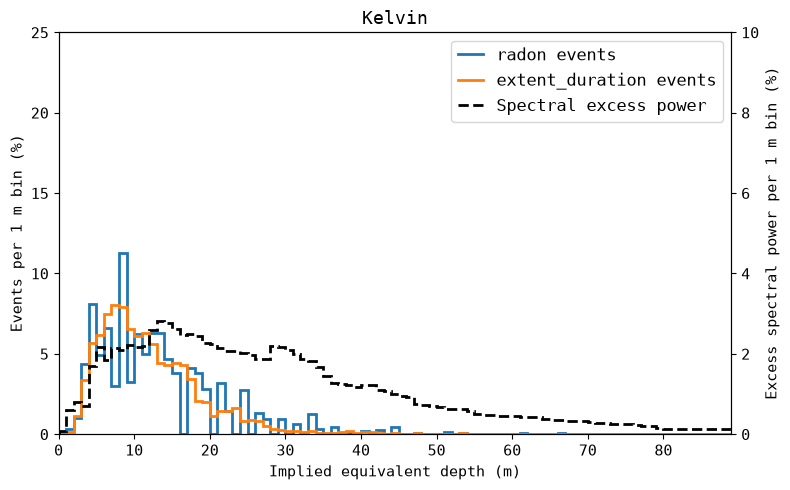

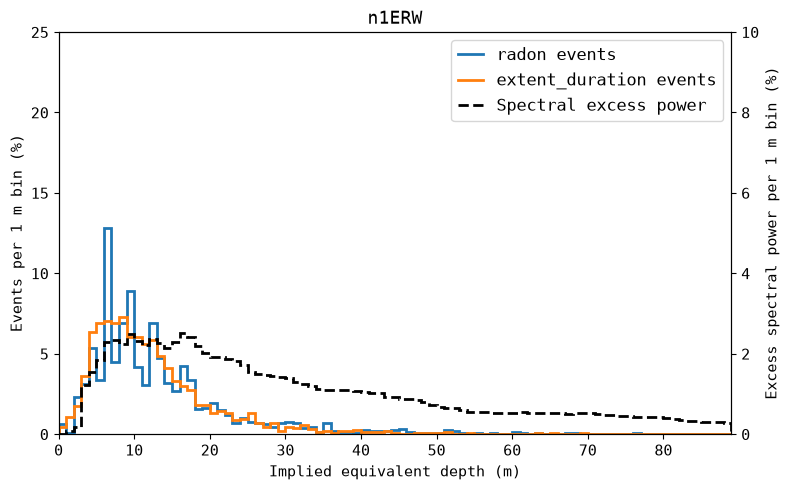

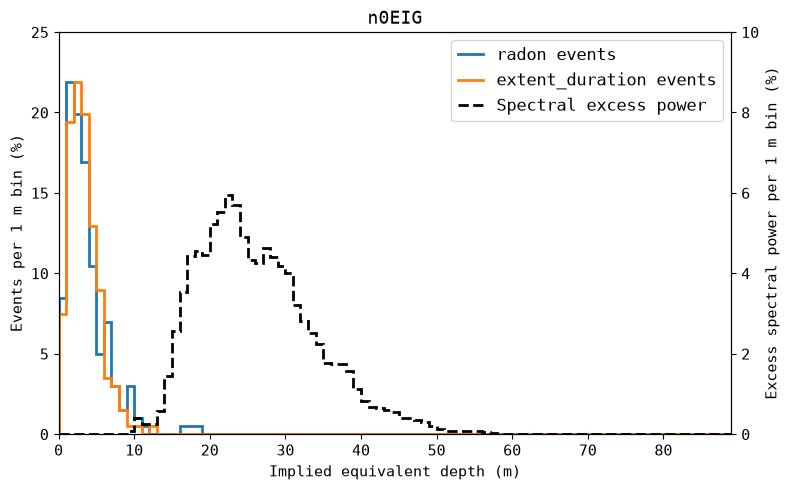

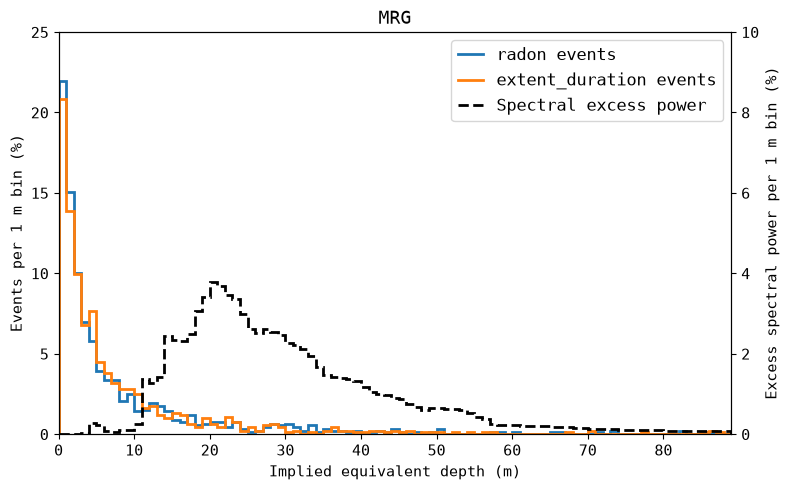

In [108]:
for wave, profile in profiles.items():

    fig, ax = plt.subplots(figsize=(8, 5))
    events = wave_event_records[wave]
    h_edges = np.arange(0.0, 90.0, 1)

    #
    # Event - based estimation
    #
    for estimator in ["radon", "extent_duration"]:
        # Keep valid inputs for the assertion in your function.
        valid_events = events[
            ["mean_width_deg", f"{estimator}_m_s"]
        ].replace([np.inf, -np.inf], np.nan).dropna()

        valid_events = valid_events[
            valid_events["mean_width_deg"] > 0
        ]

        cg = valid_events.apply(
            lambda row: implied_gravity_wave_speed(
                wave=wave,
                phase_speed=row[f"{estimator}_m_s"],
                width_deg=row["mean_width_deg"],
            ),
            axis=1,
            result_type="reduce",
        )

        h_eff = cg**2 / 9.80665

        # Store results back in the original DataFrame.
        events[f"c0_{estimator}_m_s"] = cg
        events[f"h_{estimator}_m"] = h_eff

        
        counts = stats.binned_statistic(
            h_eff.replace([np.inf, -np.inf], np.nan).dropna(),
            values=None,
            bins=h_edges,
            statistic='count'
        ).statistic
        total = h_eff.replace([np.inf, -np.inf], np.nan).dropna().size

        if counts.sum() > 0:
            ax.stairs(
                100 * counts / total,
                h_edges,
                linewidth=2,
                label=f'{estimator} events',
            )

        ax.set_ylabel("Events per 1 m bin (%)")

        # ax.hist(
        #     h_eff.replace([np.inf, -np.inf], np.nan).dropna(),
        #     bins=bins,
        #     histtype="step",
        #     linewidth=2,
        #     label=estimator
        # )

    ax.set(
        xlabel="Implied equivalent depth (m)",
        ylabel="Number of events",
        title=wave,
    )
    ax.legend(loc='upper right')


    #
    # Excess spectral power ridge based estimation
    #
    ax2 = ax.twinx()

    power = (
        spectral_power[profile.symmetry]
        .sortby("frequency")
        .sortby("zonal_wavenumber")
        .sel(zonal_wavenumber=slice(profile.k_min, profile.k_max))
    )

    excess = (power - bg).clip(min=0)
    excess = excess.where(np.isfinite(excess), 0).compute()

    # Frequency-cell edges, clipped to the profile's frequency box.
    df = float(power.frequency.diff("frequency").mean())
    f_lower = (power.frequency - df / 2).clip(min=profile.frequency_min)
    f_upper = (power.frequency + df / 2).clip(max=profile.frequency_max)

    # Dispersion curves at the depth-bin edges.
    # All resting-state branches approach zero frequency as h approaches zero.
    curves = xr.DataArray(
        [
            profile_curve_frequency(
                profile.curve_name,
                power.zonal_wavenumber,
                h,
                meridional_mode_number=profile.meridional_mode_number,
            )
            if h > 0 else np.zeros(power.sizes["zonal_wavenumber"])
            for h in h_edges
        ],
        dims=["h", "zonal_wavenumber"],
        coords={
            "h": h_edges,
            "zonal_wavenumber": power.zonal_wavenumber,
        },
    )

    bin_power = []

    for h0, h1 in zip(h_edges[:-1], h_edges[1:]):
        lower_curve = curves.sel(h=h0, drop=True)
        upper_curve = curves.sel(h=h1, drop=True)

        # Split frequency-cell power according to overlap with this depth band.
        overlap = (
            np.minimum(f_upper, upper_curve)
            - np.maximum(f_lower, lower_curve)
        ).clip(min=0) / df

        bin_power.append((excess * overlap).sum().item())

    bin_power = np.asarray(bin_power)
    box_fraction = (f_upper - f_lower).clip(min=0) / df
    total = (excess * box_fraction).sum().item()

    if total > 0:
        ax2.stairs(
            100 * bin_power / total,
            h_edges,
            color="black",
            linestyle="--",
            linewidth=2,
            label="Spectral excess power",
        )

    ax.set_ylabel("Events per 1 m bin (%)")
    ax2.set_ylabel("Excess spectral power per 1 m bin (%)")

    ax.set_xlim(h_edges[0], h_edges[-1])
    ax.set_ylim(bottom=0, top=25)
    ax2.set_ylim(bottom=0, top=10)

    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(
        handles1 + handles2,
        labels1 + labels2,
        loc="upper right",
    )

    ax.figure.tight_layout()

    
    save_figure(fig, f'{wave}_implied_depth_event_vs_spectral.pdf')

# Event identification illustration

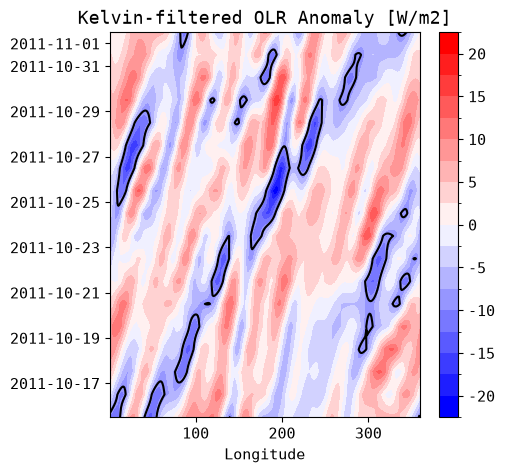

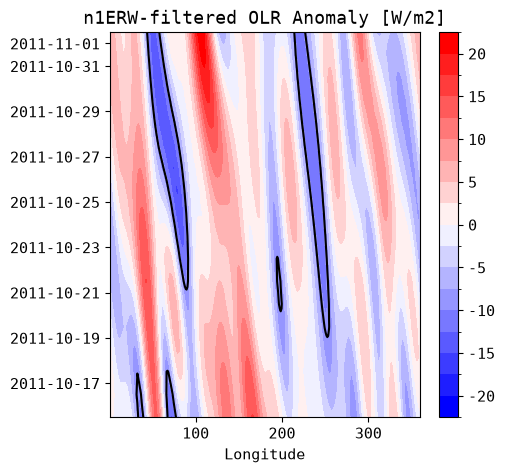

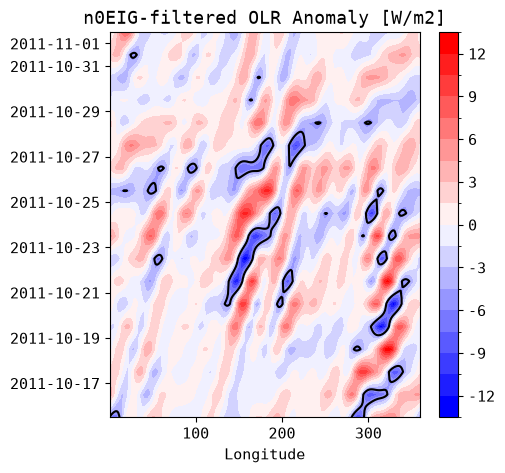

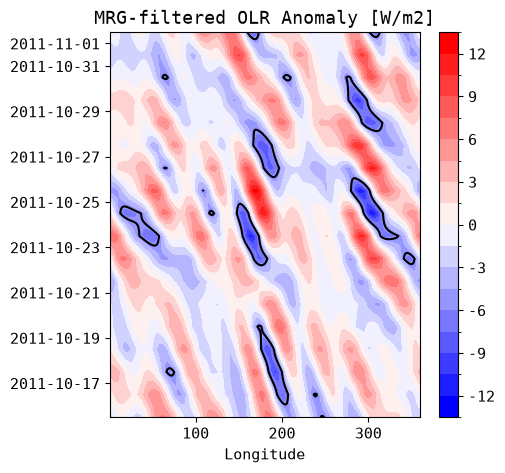

In [122]:
THRESH_SIGMA = 1.5
MIN_DURATION_DAYS = 3.0


for wave, profile in profiles.items():
    wave_data = load_wave_filtered_olr(wave)
    field = wave_data.sel(
        {
            "lat": slice(0, None),
            "time": slice("2011-10-15", "2011-11-01")
        }
    )

    hov = (
        field.weighted(np.cos(np.deg2rad(field.lat)))
        .mean("lat")
        .transpose("time", "lon")
        .compute()
    )

    olr_std = hov.std().item()
    event_threshold = - THRESH_SIGMA * olr_std

    fig, ax = plt.subplots(figsize=(5, 5))
    hov.plot.contourf(
        ax=ax,
        y="time",
        cmap=plt.cm.bwr,
        levels=20,
        cbar_kwargs={
            'label': None
        }

    )

    hov.plot.contour(
        ax=ax,
        y="time",
        levels=[event_threshold],
        colors='black',
        negative_linestyles='solid'
    )
    # candidate_event_mask = hov <= -event_threshold

    # # Eight-neighbour connectivity includes diagonally touching pixels.
    # labels, n_candidates = ndimage.label(
    #     candidate_event_mask,
    #     structure=np.ones((3, 3), dtype=bool),
    # )
    # candidate_slices = ndimage.find_objects(labels)


    ax.set_title(f'{wave}-filtered OLR Anomaly [W/m2]')
    ax.set(
        xlabel='Longitude',
        ylabel=None
    )

In [ ]:
THRESH_SIGMA = 1.5
MIN_DURATION_DAYS = 3.0

event_records = []

for profile in profiles:
    wave_data = load_wave_filtered_olr(profile)
    field = wave_data.sel(
        {
            "lat": slice(0, None)
        }
    )

    hov = (
        field.weighted(np.cos(np.deg2rad(field.lat)))
        .mean("lat")
        .transpose("time", "lon")
        .compute()
    )

    olr_std = hov.std().item()
    event_threshold = THRESH_SIGMA * olr_std
    candidate_event_mask = hov <= -event_threshold

    # Eight-neighbour connectivity includes diagonally touching pixels.
    labels, n_candidates = ndimage.label(
        candidate_event_mask,
        structure=np.ones((3, 3), dtype=bool),
    )
    candidate_slices = ndimage.find_objects(labels)


    for event_id, (time_slice, lon_slice) in enumerate(candidate_slices, start=1):
        clear_output()
        print(f'Processing  {profile} Event {event_id} of {len(candidate_slices)}')


        event_hov = hov.isel(time=time_slice, lon=lon_slice)
        event_mask = xr.DataArray(
            labels[time_slice, lon_slice] == event_id,
            dims=event_hov.dims,
            coords=event_hov.coords,
        )

        # Check duration
        duration_days = (
            (event_hov.time[-1] - event_hov.time[0]) / np.timedelta64(1, "D")
        ).item()

        if duration_days <= MIN_DURATION_DAYS:
            continue
        print(duration_days)


        #
        # Get event widths for each time
        #
        widths = xr.full_like(event_hov.time, float("nan"), dtype=float)

        for t in event_hov.time:
            event_row = event_hov.sel(time=t).where(event_mask.sel(time=t))
            if not (event_row < 0).any().item():
                continue

            trough_lon = event_row.idxmin("lon").item()
            row = hov.sel(time=t).sortby("lon")

            # Copies on either side allow the search to cross the longitude seam.
            row = xr.concat([
                row.assign_coords(lon=row.lon - 360),
                row,
                row.assign_coords(lon=row.lon + 360),
            ], dim="lon")

            left = row.where(
                (row.lon < trough_lon) & (row >= 0), drop=True
            )
            right = row.where(
                (row.lon > trough_lon) & (row >= 0), drop=True
            )

            if not left.sizes["lon"] or not right.sizes["lon"]:
                continue

            segment = row.sel(lon=slice(
                left.lon.max().item(),
                right.lon.min().item(),
            ))
            if not segment.notnull().all().item():
                continue

            left_outer = segment.isel(lon=0)
            left_inner = segment.isel(lon=1)
            right_inner = segment.isel(lon=-2)
            right_outer = segment.isel(lon=-1)

            left_zero = (
                left_outer.lon
                - left_outer * (left_inner.lon - left_outer.lon)
                / (left_inner - left_outer)
            )
            right_zero = (
                right_inner.lon
                - right_inner * (right_outer.lon - right_inner.lon)
                / (right_outer - right_inner)
            )

            widths.loc[{"time": t}] = (right_zero - left_zero).item()

        #
        # Get phase speeds for each wave event
        #
        metres_per_degree = 2 * np.pi * 6_371_000 / 360

        # Preserve all event timestamps.
        amplitude = (
            (-event_hov).where(event_mask, 0)
            .clip(min=0)
            .fillna(0)
        )
        amplitude = amplitude.reindex(
            lon=hov.lon, fill_value=0
        ).sortby("lon")

        elapsed_seconds = (
            (amplitude.time - amplitude.time[0])
            / np.timedelta64(1, "s")
        )

        # Circular amplitude-weighted centre.
        angle = np.deg2rad(amplitude.lon)
        centre_lon = np.rad2deg(np.arctan2(
            (amplitude * np.sin(angle)).sum("lon"),
            (amplitude * np.cos(angle)).sum("lon"),
        ))

        # Unwrap movement across the longitude seam.
        steps = (centre_lon.diff("time") + 180) % 360 - 180
        centre_unwrapped = xr.concat([
            centre_lon.isel(time=slice(0, 1)),
            centre_lon.isel(time=0) + steps.cumsum("time"),
        ], dim="time")

        speed_extent = (
            (centre_unwrapped[-1] - centre_unwrapped[0])
            * metres_per_degree / elapsed_seconds[-1]
        ).item()

        # Periodic field for the Radon projections.
        periodic_amplitude = xr.concat([
            amplitude.assign_coords(lon=amplitude.lon - 360),
            amplitude,
            amplitude.assign_coords(lon=amplitude.lon + 360),
        ], dim="lon")

        origins = amplitude.lon.rename({"lon": "origin"})
        lon_min = amplitude.lon.min().item()

        radon_scores = xr.DataArray(
            float("nan"),
            dims=["speed"],
            coords={"speed": np.linspace(-50, 50, 201)},
        )

        for speed in radon_scores.speed:
            path = (
                origins
                + speed.item() * elapsed_seconds / metres_per_degree
            )
            path = (path - lon_min) % 360 + lon_min

            along_paths = periodic_amplitude.interp(lon=path)
            projection = (
                along_paths.assign_coords(time=elapsed_seconds)
                .integrate("time")
            )
            radon_scores.loc[{"speed": speed}] = (
                projection**2
            ).sum("origin").item()

        speed_radon = radon_scores.idxmax("speed").item()

        phase_speeds = xr.DataArray(
            [speed_radon, speed_extent],
            dims=["estimator"],
            coords={"estimator": ["radon", "extent_duration"]},
            name="phase_speed",
            attrs={"units": "m s-1", "positive": "eastward"},
        )

        #
        # Record event information
        #
        event_records.append({
            "wave": profile,
            "start": event_hov.time.values[0],
            "stop": event_hov.time.values[-1],
            "max_olr_sigma": event_hov.where(event_mask).max().item() / olr_std,
            "min_olr_sigma": event_hov.where(event_mask).min().item() / olr_std,
            "mean_width_deg": widths.mean("time").item(),
            "max_width_deg": widths.max("time").item(),
            "min_width_deg": widths.min("time").item(),
            "radon_m_s": phase_speeds.sel(
                estimator="radon"
            ).item(),
            "extent_duration_m_s": phase_speeds.sel(
                estimator="extent_duration"
            ).item(),
        })

events = pd.DataFrame(event_records)   

Processing  Kelvin Event 3520 of 10863
3.0


KeyboardInterrupt: 